# Laboratory Assignment 8: High-Performance Big Data Analytics Using R

**Dataset:** NYC TLC Yellow Taxi Trip Records — January 2026  
**Tools:** `data.table`, functional programming, vectorized R, parallel processing, benchmarking, and `ggplot2`

## Objectives
- Prepare and clean large-scale taxi trip data.
- Analyze travel demand, fares, revenue, routes, distances, and payment preferences.
- Compare functional, vectorized, and `data.table` implementations.
- Compare sequential and parallel processing.
- Benchmark execution time and discuss memory use, scalability, and readability.
- Visualize findings and make evidence-based recommendations.

## 1. Packages and environment

This notebook expects the two files to be present in the Colab **Files / content** area:
- `yellow_tripdata_2026-01.parquet`
- `taxi_zone_lookup.csv`

The code reads them directly from `/content`; there is no upload widget.

In [1]:
required_packages <- c(
  "arrow", "data.table", "ggplot2", "lubridate",
  "foreach", "doParallel", "microbenchmark", "purrr"
)

missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]

if (length(missing_packages) > 0) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}

invisible(lapply(required_packages, library, character.only = TRUE))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘assertthat’, ‘iterators’



Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following object is masked from ‘package:arrow’:

    duration


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose




In [2]:
trip_file <- "/content/yellow_tripdata_2026-01.parquet"
zone_file <- "/content/taxi_zone_lookup.csv"

stopifnot(file.exists(trip_file), file.exists(zone_file))

## 2. Dataset acquisition and inspection

The trip data is read from Parquet using `arrow`. The zone lookup CSV maps taxi location IDs to borough and zone names.

In [3]:
trips_raw <- as.data.table(arrow::read_parquet(trip_file))
zones <- fread(zone_file)

dim(trips_raw)
names(trips_raw)
str(trips_raw)
summary(trips_raw)

[1] 3724889      20

[1] "VendorID"              "tpep_pickup_datetime"  "tpep_dropoff_datetime"
 [4] "passenger_count"       "trip_distance"         "RatecodeID"           
 [7] "store_and_fwd_flag"    "PULocationID"          "DOLocationID"         
[10] "payment_type"          "fare_amount"           "extra"                
[13] "mta_tax"               "tip_amount"            "tolls_amount"         
[16] "improvement_surcharge" "total_amount"          "congestion_surcharge" 
[19] "Airport_fee"           "cbd_congestion_fee"

Classes ‘data.table’ and 'data.frame':	3724889 obs. of  20 variables:
 $ VendorID             : int  2 1 1 2 2 2 1 1 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2026-01-01 00:54:04" "2026-01-01 00:34:04" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2026-01-01 00:59:37" "2026-01-01 00:39:47" ...
 $ passenger_count      : int  1 0 0 4 0 2 1 0 1 3 ...
 $ trip_distance        : num  0.97 0.9 1.4 5.58 2.16 2.33 1.3 2.9 5.34 1.83 ...
 $ RatecodeID           : int  1 1 1 1 1 1 1 1 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  239 163 43 142 88 144 142 50 161 237 ...
 $ DOLocationID         : int  238 162 237 209 144 137 50 234 45 263 ...
 $ payment_type         : int  1 2 1 1 1 1 2 1 1 1 ...
 $ fare_amount          : num  7.2 7.9 10.7 38.7 13.5 14.2 11.4 22.6 37.3 10.7 ...
 $ extra                : num  1 4.25 4.25 1 1 1 4.25 4.25 1 1 ...
 $ mta_tax              : num  0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 ...
 $ tip_amount           : 

    VendorID     tpep_pickup_datetime          tpep_dropoff_datetime        
 Min.   :1.000   Min.   :2025-12-31 23:57:29   Min.   :2025-12-31 23:57:32  
 1st Qu.:2.000   1st Qu.:2026-01-09 17:51:59   1st Qu.:2026-01-09 18:08:47  
 Median :2.000   Median :2026-01-16 21:20:56   Median :2026-01-16 21:36:14  
 Mean   :1.874   Mean   :2026-01-17 01:44:52   Mean   :2026-01-17 02:02:03  
 3rd Qu.:2.000   3rd Qu.:2026-01-24 07:25:11   3rd Qu.:2026-01-24 07:40:22  
 Max.   :7.000   Max.   :2026-02-01 00:45:01   Max.   :2026-02-01 23:35:31  
                                                                            
 passenger_count   trip_distance         RatecodeID      store_and_fwd_flag 
 Min.   :0.000     Min.   :0.000e+00   Min.   : 1.000    Length   :3724889  
 1st Qu.:1.000     1st Qu.:1.000e+00   1st Qu.: 1.000    N.unique :      2  
 Median :1.000     Median :1.810e+00   Median : 1.000    N.blank  :      0  
 Mean   :1.256     Mean   :6.456e+00   Mean   : 5.219    Min.nchar:      1  

In [4]:
dim(zones)
names(zones)
head(zones)
summary(zones)

[1] 265   4

[1] "LocationID"   "Borough"      "Zone"         "service_zone"

LocationID,Borough,Zone,service_zone
<int>,<chr>,<chr>,<chr>
1,EWR,Newark Airport,EWR
2,Queens,Jamaica Bay,Boro Zone
3,Bronx,Allerton/Pelham Gardens,Boro Zone
4,Manhattan,Alphabet City,Yellow Zone
5,Staten Island,Arden Heights,Boro Zone
6,Staten Island,Arrochar/Fort Wadsworth,Boro Zone


   LocationID       Borough           Zone        service_zone
 Min.   :  1   Length   :265   Length   :265   Length   :265  
 1st Qu.: 67   N.unique :  8   N.unique :262   N.unique :  5  
 Median :133   N.blank  :  0   N.blank  :  0   N.blank  :  0  
 Mean   :133   Min.nchar:  3   Min.nchar:  3   Min.nchar:  3  
 3rd Qu.:199   Max.nchar: 13   Max.nchar: 45   Max.nchar: 11  
 Max.   :265                                                  

## 3. Data preparation and cleaning

The notebook standardizes column names, checks required fields, removes exact duplicate rows, validates key numeric fields, converts timestamps, and derives temporal attributes. Invalid records are excluded from the main analytical dataset.

In [5]:
setnames(trips_raw, names(trips_raw), tolower(names(trips_raw)))
setnames(zones, names(zones), tolower(names(zones)))

required_columns <- c(
  "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "pulocationid", "dolocationid", "passenger_count",
  "trip_distance", "payment_type", "fare_amount",
  "tip_amount", "tolls_amount", "total_amount"
)

missing_columns <- setdiff(required_columns, names(trips_raw))
if (length(missing_columns) > 0) {
  stop(paste("Expected columns missing:", paste(missing_columns, collapse = ", ")))
}

rows_before <- nrow(trips_raw)
trips <- unique(trips_raw)
duplicate_rows_removed <- rows_before - nrow(trips)

list(
  rows_before = rows_before,
  duplicate_rows_removed = duplicate_rows_removed,
  rows_after_duplicate_removal = nrow(trips)
)

$rows_before
[1] 3724889

$duplicate_rows_removed
[1] 0

$rows_after_duplicate_removal
[1] 3724889

In [6]:
trips[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, tz = "UTC")]
trips[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, tz = "UTC")]

numeric_columns <- intersect(
  c("pulocationid", "dolocationid", "passenger_count", "trip_distance",
    "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"),
  names(trips)
)

trips[, (numeric_columns) := lapply(.SD, as.numeric), .SDcols = numeric_columns]

cleaning_missing <- trips[, lapply(.SD, function(x) sum(is.na(x))), .SDcols = required_columns]
cleaning_missing

tpep_pickup_datetime,tpep_dropoff_datetime,pulocationid,dolocationid,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,tolls_amount,total_amount
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
0,0,0,0,1088058,0,0,0,0,0,0


In [7]:
rows_before_validation <- nrow(trips)

trips <- trips[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  tpep_dropoff_datetime >= tpep_pickup_datetime &
  !is.na(trip_distance) & trip_distance > 0 &
  !is.na(fare_amount) & fare_amount >= 0 &
  !is.na(total_amount) & total_amount >= 0 &
  !is.na(pulocationid) & !is.na(dolocationid)
]

rows_after_validation <- nrow(trips)

data_quality_summary <- data.table(
  measure = c("Rows before validation", "Rows after validation", "Rows excluded by validation"),
  value = c(rows_before_validation, rows_after_validation,
            rows_before_validation - rows_after_validation)
)

data_quality_summary

measure,value
<chr>,<int>
Rows before validation,3724889
Rows after validation,3562058
Rows excluded by validation,162831


In [8]:
trips[, `:=`(
  pickup_hour = hour(tpep_pickup_datetime),
  pickup_day = day(tpep_pickup_datetime),
  pickup_weekday = wday(tpep_pickup_datetime, label = TRUE, abbr = FALSE, week_start = 1),
  pickup_month = month(tpep_pickup_datetime, label = TRUE, abbr = FALSE),
  trip_duration_min = as.numeric(difftime(
    tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins"
  ))
)]

trips <- trips[!is.na(trip_duration_min) & trip_duration_min >= 0]
trips[, .(rows = .N, columns = ncol(trips))]

rows,columns
<int>,<int>
3562058,25


### Memory-conscious column selection

Keep the fields required for the analyses. This reduces memory use compared with retaining every source column.

In [9]:
analysis_columns <- intersect(
  c("tpep_pickup_datetime", "tpep_dropoff_datetime",
    "pulocationid", "dolocationid", "passenger_count",
    "trip_distance", "payment_type", "fare_amount",
    "tip_amount", "tolls_amount", "total_amount",
    "pickup_hour", "pickup_day", "pickup_weekday",
    "pickup_month", "trip_duration_min"),
  names(trips)
)

trips <- trips[, ..analysis_columns]
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,1535443,82.1,2861028,152.8,2706618,144.6
Vcells,115975776,884.9,325063850,2480.1,269317478,2054.8


### Join pickup and drop-off zone information

The two joins add readable pickup and drop-off borough and zone labels. Location IDs that are not in the lookup table remain unmatched.

In [10]:
pickup_zones <- copy(zones)
setnames(
  pickup_zones,
  old = intersect(c("locationid", "borough", "zone", "service_zone"), names(pickup_zones)),
  new = paste0("pickup_", intersect(c("locationid", "borough", "zone", "service_zone"), names(pickup_zones)))
)

dropoff_zones <- copy(zones)
setnames(
  dropoff_zones,
  old = intersect(c("locationid", "borough", "zone", "service_zone"), names(dropoff_zones)),
  new = paste0("dropoff_", intersect(c("locationid", "borough", "zone", "service_zone"), names(dropoff_zones)))
)

trips <- merge(
  trips, pickup_zones,
  by.x = "pulocationid", by.y = "pickup_locationid",
  all.x = TRUE, sort = FALSE
)

trips <- merge(
  trips, dropoff_zones,
  by.x = "dolocationid", by.y = "dropoff_locationid",
  all.x = TRUE, sort = FALSE
)

trips[, .(
  total_trips = .N,
  missing_pickup_zone = sum(is.na(pickup_zone)),
  missing_dropoff_zone = sum(is.na(dropoff_zone))
)]

total_trips,missing_pickup_zone,missing_dropoff_zone
<int>,<int>,<int>
3562058,0,0


## 4. Transportation data analytics

The following summaries answer the required questions using `data.table` grouping and aggregation.

In [11]:
trips_by_hour <- trips[, .(trip_count = .N), by = pickup_hour][order(pickup_hour)]
trips_by_weekday <- trips[, .(trip_count = .N), by = pickup_weekday][order(pickup_weekday)]
trips_by_month <- trips[, .(trip_count = .N), by = pickup_month]
fare_revenue_by_hour <- trips[, .(
  average_fare = mean(fare_amount, na.rm = TRUE),
  total_revenue = sum(total_amount, na.rm = TRUE),
  trip_count = .N
), by = pickup_hour][order(pickup_hour)]

trips_by_hour
trips_by_weekday
trips_by_month
fare_revenue_by_hour

pickup_hour,trip_count
<int>,<int>
0,109369
1,75924
2,52641
3,37562
4,27740
5,31942
6,62383
7,111593
8,145804


pickup_weekday,trip_count
<ord>,<int>
Monday,358979
Tuesday,458911
Wednesday,480467
Thursday,622473
Friday,617954
Saturday,658124
Sunday,365150


pickup_month,trip_count
<ord>,<int>
January,3562052
December,5
February,1


pickup_hour,average_fare,total_revenue,trip_count
<int>,<dbl>,<dbl>,<int>
0,21.96915,3299769.9,109369
1,21.63954,2226765.8,75924
2,20.41177,1464514.0,52641
3,21.00532,1063607.9,37562
4,24.19035,879442.6,27740
5,26.95001,1109541.6,31942
6,25.85453,2067232.6,62383
7,23.93571,3497038.8,111593
8,22.58721,4384393.5,145804


In [12]:
top_routes <- trips[, .(
  trip_count = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE)
), by = .(pulocationid, dolocationid, pickup_zone, dropoff_zone)][
  order(-trip_count)
][1:min(15, .N)]

highest_revenue_routes <- trips[, .(
  trip_count = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE)
), by = .(pulocationid, dolocationid, pickup_zone, dropoff_zone)][
  order(-total_revenue)
][1:min(15, .N)]

top_routes
highest_revenue_routes

pulocationid,dolocationid,pickup_zone,dropoff_zone,trip_count,total_revenue,average_fare
<int>,<int>,<chr>,<chr>,<int>,<dbl>,<dbl>
237,236,Upper East Side South,Upper East Side North,23836,383166.2,9.047871
236,237,Upper East Side North,Upper East Side South,20668,351816.4,10.038615
236,236,Upper East Side North,Upper East Side North,16465,227660.6,7.257796
237,237,Upper East Side South,Upper East Side South,15207,219101.9,7.619150
161,237,Midtown Center,Upper East Side South,10158,192046.7,10.754996
237,161,Upper East Side South,Midtown Center,9351,171375.4,10.681274
142,239,Lincoln Square East,Upper West Side South,8926,137391.0,8.286098
239,238,Upper West Side South,Upper West Side North,8743,124944.1,7.601828
239,142,Upper West Side South,Lincoln Square East,8425,126826.7,8.220411


pulocationid,dolocationid,pickup_zone,dropoff_zone,trip_count,total_revenue,average_fare
<int>,<int>,<chr>,<chr>,<int>,<dbl>,<dbl>
132,265,JFK Airport,Outside of NYC,7146,879258.5,102.865241
132,230,JFK Airport,Times Sq/Theatre District,4902,476810.7,71.131257
237,236,Upper East Side South,Upper East Side North,23836,383166.2,9.047871
138,230,LaGuardia Airport,Times Sq/Theatre District,4678,375229.8,50.001124
236,237,Upper East Side North,Upper East Side South,20668,351816.4,10.038615
132,48,JFK Airport,Clinton East,2586,249569.1,71.237158
132,164,JFK Airport,Midtown South,2465,242751.2,70.773249
236,236,Upper East Side North,Upper East Side North,16465,227660.6,7.257796
138,161,LaGuardia Airport,Midtown Center,2934,226195.4,47.098517


In [13]:
distance_fare_summary <- trips[, .(
  trip_count = .N,
  average_distance = mean(trip_distance, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE),
  median_fare = median(fare_amount, na.rm = TRUE)
), by = cut(
  trip_distance,
  breaks = c(0, 1, 2, 5, 10, 20, Inf),
  include.lowest = TRUE,
  right = TRUE
)]

payment_by_borough <- trips[, .(
  trip_count = .N,
  total_revenue = sum(total_amount, na.rm = TRUE)
), by = .(pickup_borough, payment_type)][order(pickup_borough, -trip_count)]

distance_fare_summary
payment_by_borough

cut,trip_count,average_distance,average_fare,median_fare
<fct>,<int>,<dbl>,<dbl>,<dbl>
"[0,1]",802158,0.673342,9.566069,7.90
"(1,2]",1076274,1.467098,13.292782,12.10
"(5,10]",408902,7.153320,34.994816,33.18
"(2,5]",1000514,3.088240,21.731348,19.80
"(10,20]",243893,14.437806,57.794946,56.90
"(20,Inf]",30317,403.367937,90.866659,70.00


pickup_borough,payment_type,trip_count,total_revenue
<chr>,<dbl>,<int>,<dbl>
Bronx,1,17722,724264.10
Bronx,0,16963,541122.22
Bronx,2,566,14266.31
Bronx,4,38,1725.44
Bronx,3,24,378.60
Brooklyn,0,99433,3554644.12
Brooklyn,1,44969,1557057.00
Brooklyn,2,1910,48496.79
Brooklyn,4,182,6391.04


In [14]:
overall_summary <- trips[, .(
  trip_count = .N,
  average_distance = mean(trip_distance, na.rm = TRUE),
  median_distance = median(trip_distance, na.rm = TRUE),
  average_fare = mean(fare_amount, na.rm = TRUE),
  median_fare = median(fare_amount, na.rm = TRUE),
  total_revenue = sum(total_amount, na.rm = TRUE),
  average_trip_duration_min = mean(trip_duration_min, na.rm = TRUE)
)]

payment_distribution <- trips[, .(trip_count = .N), by = payment_type][
  , share_percent := 100 * trip_count / sum(trip_count)
][order(-trip_count)]

top_pickup_locations <- trips[, .(trip_count = .N), by = .(pulocationid, pickup_zone, pickup_borough)][
  order(-trip_count)
][1:min(10, .N)]

top_dropoff_locations <- trips[, .(trip_count = .N), by = .(dolocationid, dropoff_zone, dropoff_borough)][
  order(-trip_count)
][1:min(10, .N)]

overall_summary
payment_distribution
top_pickup_locations
top_dropoff_locations

trip_count,average_distance,median_distance,average_fare,median_fare,total_revenue,average_trip_duration_min
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
3562058,6.705154,1.9,21.02232,15.6,105510971,17.25794


payment_type,trip_count,share_percent
<dbl>,<int>,<dbl>
1,2231447,62.644881
0,995312,27.942049
2,297883,8.362666
4,27899,0.783227
3,9517,0.267177


pulocationid,pickup_zone,pickup_borough,trip_count
<int>,<chr>,<chr>,<int>
237,Upper East Side South,Manhattan,155799
236,Upper East Side North,Manhattan,149149
132,JFK Airport,Queens,142827
161,Midtown Center,Manhattan,141624
186,Penn Station/Madison Sq West,Manhattan,107412
142,Lincoln Square East,Manhattan,106751
162,Midtown East,Manhattan,105361
230,Times Sq/Theatre District,Manhattan,102131
79,East Village,Manhattan,97136


dolocationid,dropoff_zone,dropoff_borough,trip_count
<int>,<chr>,<chr>,<int>
236,Upper East Side North,Manhattan,152605
237,Upper East Side South,Manhattan,142386
161,Midtown Center,Manhattan,117277
170,Murray Hill,Manhattan,95987
239,Upper West Side South,Manhattan,94169
230,Times Sq/Theatre District,Manhattan,94038
142,Lincoln Square East,Manhattan,94012
141,Lenox Hill West,Manhattan,93093
68,East Chelsea,Manhattan,86756


## 5. Functional programming, vectorization, and `data.table`

These sections calculate equivalent hourly trip counts using different approaches, then benchmark them. Results should agree, while runtime can differ.

In [15]:
hourly_base <- as.data.frame(trips[, .(pickup_hour)])
base_hourly_result <- as.data.frame(table(hourly_base$pickup_hour))
names(base_hourly_result) <- c("pickup_hour", "trip_count")
base_hourly_result$pickup_hour <- as.integer(as.character(base_hourly_result$pickup_hour))
base_hourly_result$trip_count <- as.integer(base_hourly_result$trip_count)

hourly_vectorized <- tabulate(trips$pickup_hour + 1L, nbins = 24L)
hourly_datatable <- trips[, .(trip_count = .N), by = pickup_hour][order(pickup_hour)]

head(base_hourly_result)
head(hourly_vectorized)
hourly_datatable

,pickup_hour,trip_count
,<int>,<int>
1,0,109369
2,1,75924
3,2,52641
4,3,37562
5,4,27740
6,5,31942


[1] 109369  75924  52641  37562  27740  31942

pickup_hour,trip_count
<int>,<int>
0,109369
1,75924
2,52641
3,37562
4,27740
5,31942
6,62383
7,111593
8,145804


In [16]:
hour_values <- 0:23

hourly_lapply <- rbindlist(lapply(hour_values, function(h) {
  data.table(pickup_hour = h, trip_count = sum(trips$pickup_hour == h, na.rm = TRUE))
}))

hourly_map <- purrr::map_dfr(hour_values, function(h) {
  data.frame(pickup_hour = h, trip_count = sum(trips$pickup_hour == h, na.rm = TRUE))
})

hourly_apply <- data.frame(
  pickup_hour = hour_values,
  trip_count = as.integer(sapply(hour_values, function(h) sum(trips$pickup_hour == h, na.rm = TRUE)))
)

head(hourly_lapply)
head(hourly_map)
head(hourly_apply)

pickup_hour,trip_count
<int>,<int>
0,109369
1,75924
2,52641
3,37562
4,27740
5,31942


,pickup_hour,trip_count
,<int>,<int>
1,0,109369
2,1,75924
3,2,52641
4,3,37562
5,4,27740
6,5,31942


,pickup_hour,trip_count
,<int>,<int>
1,0,109369
2,1,75924
3,2,52641
4,3,37562
5,4,27740
6,5,31942


In [17]:
hourly_check <- merge(
  hourly_datatable,
  data.table(pickup_hour = 0:23, vectorized_count = hourly_vectorized),
  by = "pickup_hour",
  all = TRUE
)

hourly_check[, counts_match := trip_count == vectorized_count]
hourly_check
stopifnot(all(hourly_check$counts_match))

pickup_hour,trip_count,vectorized_count,counts_match
<int>,<int>,<int>,<lgl>
0,109369,109369,TRUE
1,75924,75924,TRUE
2,52641,52641,TRUE
3,37562,37562,TRUE
4,27740,27740,TRUE
5,31942,31942,TRUE
6,62383,62383,TRUE
7,111593,111593,TRUE
8,145804,145804,TRUE


### Benchmark equivalent implementations

Benchmarking uses the same already-loaded data and equivalent hourly-count operations. Times vary by machine, dataset size, and runtime conditions.

In [18]:
benchmark_data <- trips[, .(pickup_hour)]
benchmark_results <- microbenchmark(
  base_table = table(benchmark_data$pickup_hour),
  vectorized_tabulate = tabulate(benchmark_data$pickup_hour + 1L, nbins = 24L),
  data_table = benchmark_data[, .N, by = pickup_hour],
  lapply_count = lapply(0:23, function(h) sum(benchmark_data$pickup_hour == h)),
  times = 5L
)

benchmark_results

expr,time
<fct>,<dbl>
lapply_count,238597500
data_table,69849671
lapply_count,247471067
data_table,68193503
base_table,117507719
base_table,126211881
data_table,87701532
vectorized_tabulate,11654986
lapply_count,296754247


In [19]:
benchmark_summary <- as.data.table(summary(benchmark_results))[
  , .(expr, min, median, mean, max)
][order(median)]

benchmark_summary

expr,min,median,mean,max
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
vectorized_tabulate,11.65499,17.27981,15.08588,17.51718
data_table,68.19350,70.98306,73.58725,87.70153
base_table,115.70643,118.35552,131.42856,179.36125
lapply_count,238.59750,248.83941,259.25292,296.75425


## 6. Sequential and parallel processing

The same month-partitioned hourly-count operation is executed sequentially and using `foreach` with `doParallel`. Parallel setup has overhead, so parallel execution is not guaranteed to be faster for a single month's data.

In [20]:
month_partitions <- list(january = trips[, .(pickup_hour)])

In [21]:
sequential_time <- system.time({
  sequential_results <- lapply(month_partitions, function(part) {
    part[, .(trip_count = .N), by = pickup_hour][order(pickup_hour)]
  })
})

sequential_time

   user  system elapsed 
  0.074   0.000   0.074 

In [22]:
available_cores <- parallel::detectCores(logical = TRUE)
worker_count <- max(1L, min(2L, available_cores - 1L))
cluster <- parallel::makeCluster(worker_count)
doParallel::registerDoParallel(cluster)

parallel_time <- system.time({
  parallel_results <- foreach::foreach(
    part = month_partitions,
    .packages = "data.table"
  ) %dopar% {
    part[, .(trip_count = .N), by = pickup_hour][order(pickup_hour)]
  }
})

parallel::stopCluster(cluster)
foreach::registerDoSEQ()

list(
  available_cores = available_cores,
  workers_used = worker_count,
  sequential_seconds = unname(sequential_time["elapsed"]),
  parallel_seconds = unname(parallel_time["elapsed"]),
  speedup = unname(sequential_time["elapsed"]) / unname(parallel_time["elapsed"])
)

$available_cores
[1] 2

$workers_used
[1] 1

$sequential_seconds
[1] 0.074

$parallel_seconds
[1] 0.327

$speedup
[1] 0.2262997

In [23]:
sequential_results[[1]]
parallel_results[[1]]
all.equal(
  as.data.frame(sequential_results[[1]]),
  as.data.frame(parallel_results[[1]]),
  check.attributes = FALSE
)

pickup_hour,trip_count
<int>,<int>
0,109369
1,75924
2,52641
3,37562
4,27740
5,31942
6,62383
7,111593
8,145804


pickup_hour,trip_count
<int>,<int>
0,109369
1,75924
2,52641
3,37562
4,27740
5,31942
6,62383
7,111593
8,145804


[1] TRUE

**Interpretation:** Parallel speedup is calculated as sequential elapsed time divided by parallel elapsed time. Values above 1 indicate faster parallel execution. With only one partition, setup and data-transfer overhead can outweigh any benefit. More partitions or a larger workload may be needed to demonstrate parallel scaling meaningfully.

## 7. Performance and memory evaluation

The next cells compare runtime summaries and estimate object sizes. Object size is an estimate of in-memory R objects, not total peak process memory.

In [24]:
memory_summary <- data.table(
  object = c("Raw trip data", "Cleaned and joined trips", "Zone lookup"),
  size_MB = c(
    as.numeric(object.size(trips_raw)) / 1024^2,
    as.numeric(object.size(trips)) / 1024^2,
    as.numeric(object.size(zones)) / 1024^2
  )
)

memory_summary
benchmark_summary

object,size_MB
<chr>,<dbl>
Raw trip data,483.12258148
Cleaned and joined trips,516.39531708
Zone lookup,0.02708435


expr,min,median,mean,max
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
vectorized_tabulate,11.65499,17.27981,15.08588,17.51718
data_table,68.19350,70.98306,73.58725,87.70153
base_table,115.70643,118.35552,131.42856,179.36125
lapply_count,238.59750,248.83941,259.25292,296.75425


In [25]:
best_benchmark <- benchmark_summary[which.min(median)]
slowest_benchmark <- benchmark_summary[which.max(median)]

list(
  fastest_median = best_benchmark,
  slowest_median = slowest_benchmark,
  estimated_memory = memory_summary
)

$fastest_median
                  expr      min   median     mean      max
                <fctr>    <num>    <num>    <num>    <num>
1: vectorized_tabulate 11.65499 17.27981 15.08588 17.51718

$slowest_median
           expr      min   median     mean      max
         <fctr>    <num>    <num>    <num>    <num>
1: lapply_count 238.5975 248.8394 259.2529 296.7542

$estimated_memory
                     object      size_MB
                     <char>        <num>
1:            Raw trip data 483.12258148
2: Cleaned and joined trips 516.39531708
3:              Zone lookup   0.02708435

## 8. Data visualization

All plots include titles and axis labels. Each plot should be interpreted in the context of the selected month and the cleaning rules above.

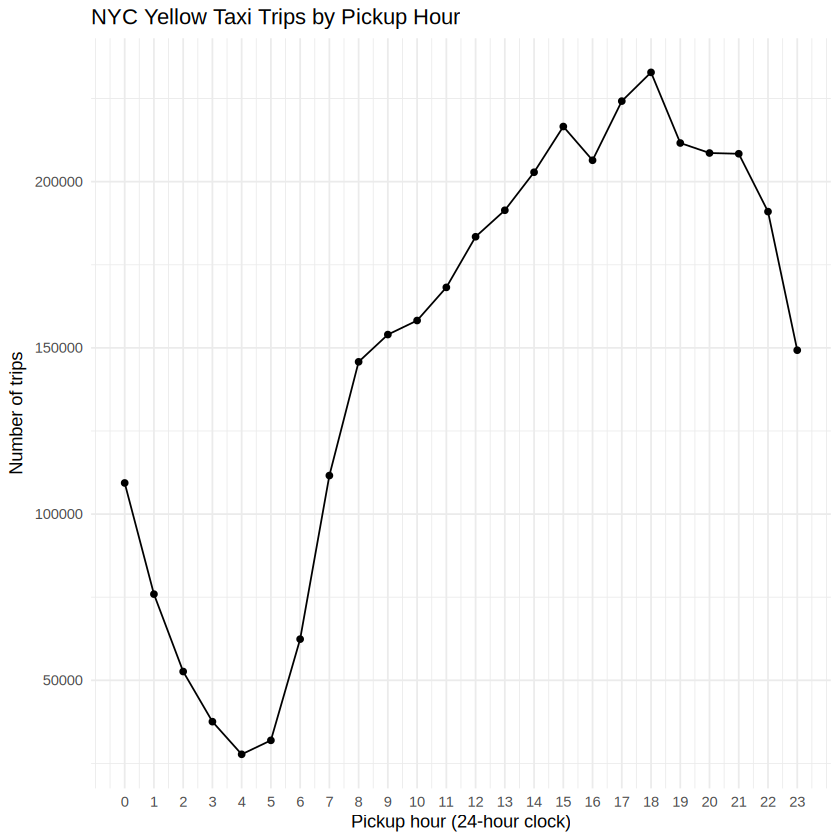

In [26]:
ggplot(trips_by_hour, aes(x = pickup_hour, y = trip_count)) +
  geom_line() +
  geom_point() +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "NYC Yellow Taxi Trips by Pickup Hour",
    x = "Pickup hour (24-hour clock)",
    y = "Number of trips"
  ) +
  theme_minimal()

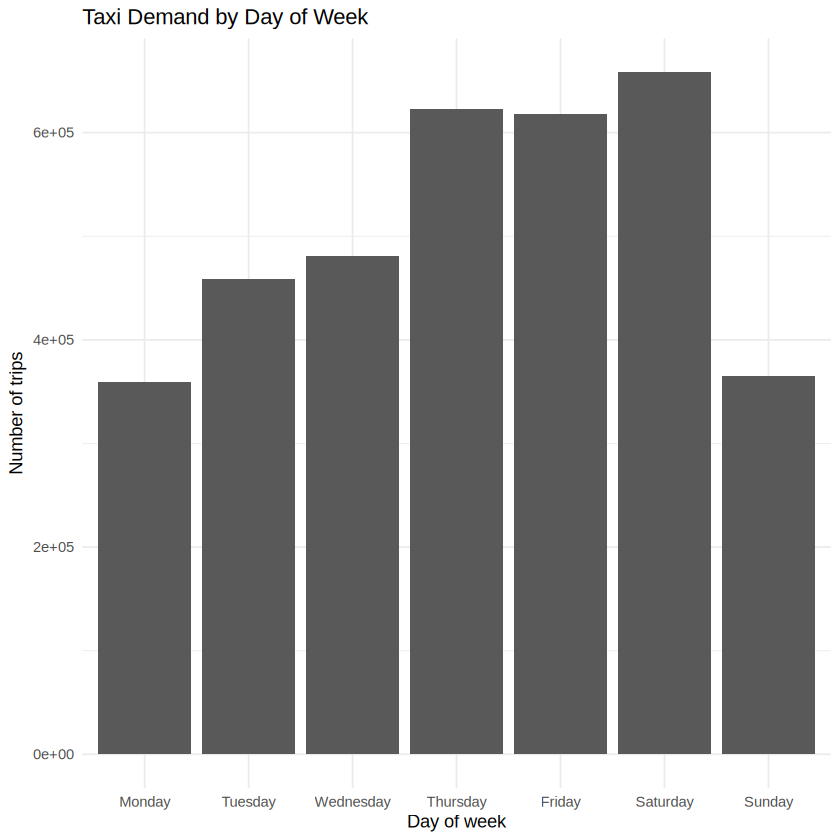

In [27]:
ggplot(trips_by_weekday, aes(x = pickup_weekday, y = trip_count)) +
  geom_col() +
  labs(
    title = "Taxi Demand by Day of Week",
    x = "Day of week",
    y = "Number of trips"
  ) +
  theme_minimal()

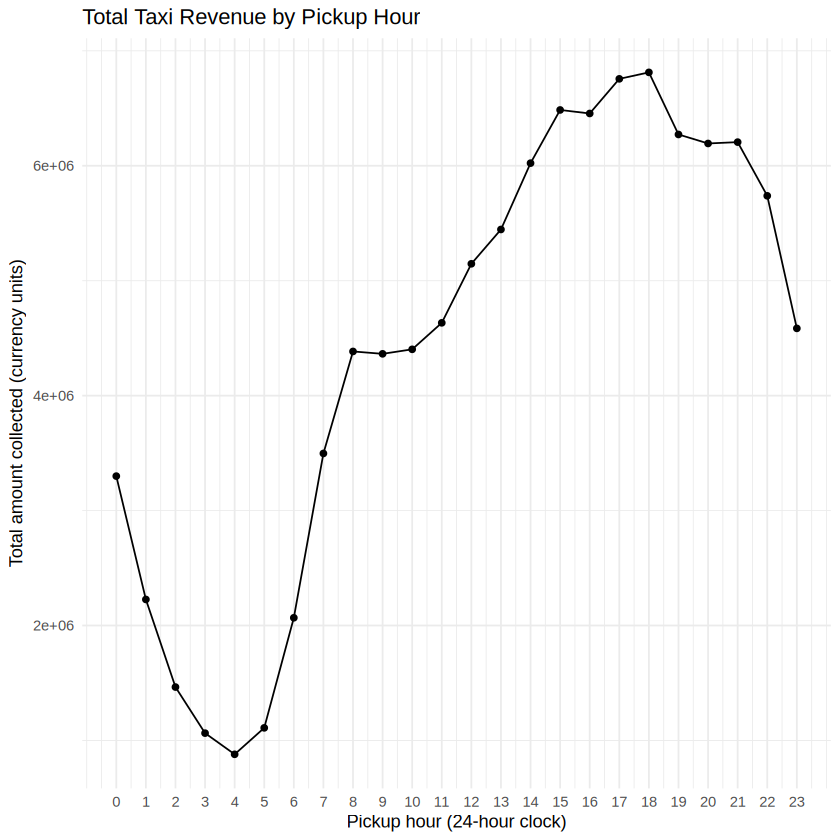

In [28]:
ggplot(fare_revenue_by_hour, aes(x = pickup_hour, y = total_revenue)) +
  geom_line() +
  geom_point() +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "Total Taxi Revenue by Pickup Hour",
    x = "Pickup hour (24-hour clock)",
    y = "Total amount collected (currency units)"
  ) +
  theme_minimal()

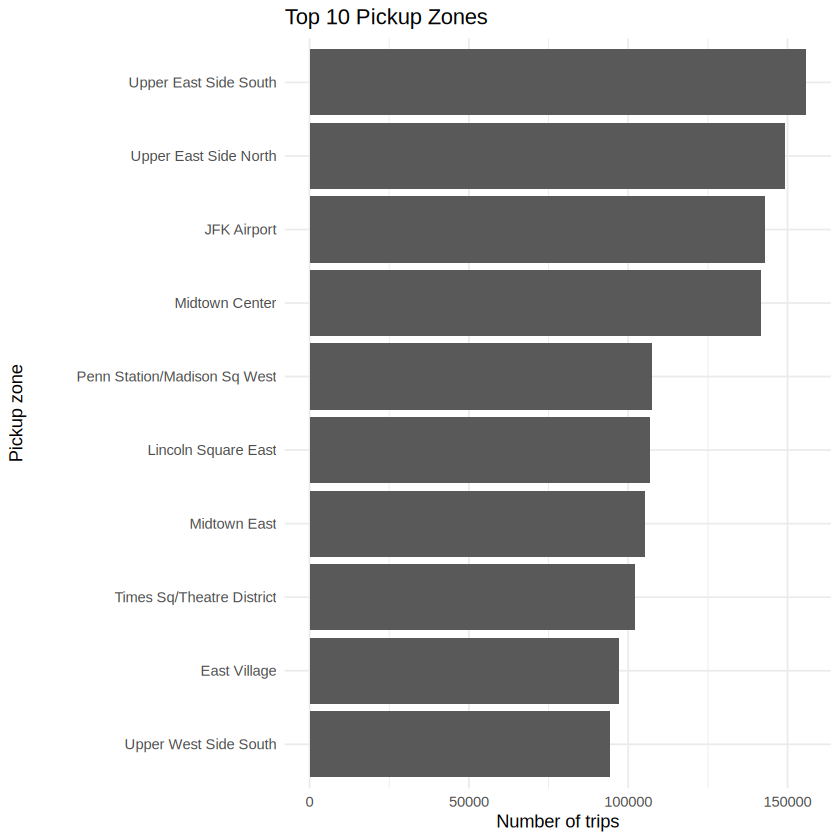

In [29]:
ggplot(top_pickup_locations, aes(x = reorder(pickup_zone, trip_count), y = trip_count)) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Top 10 Pickup Zones",
    x = "Pickup zone",
    y = "Number of trips"
  ) +
  theme_minimal()

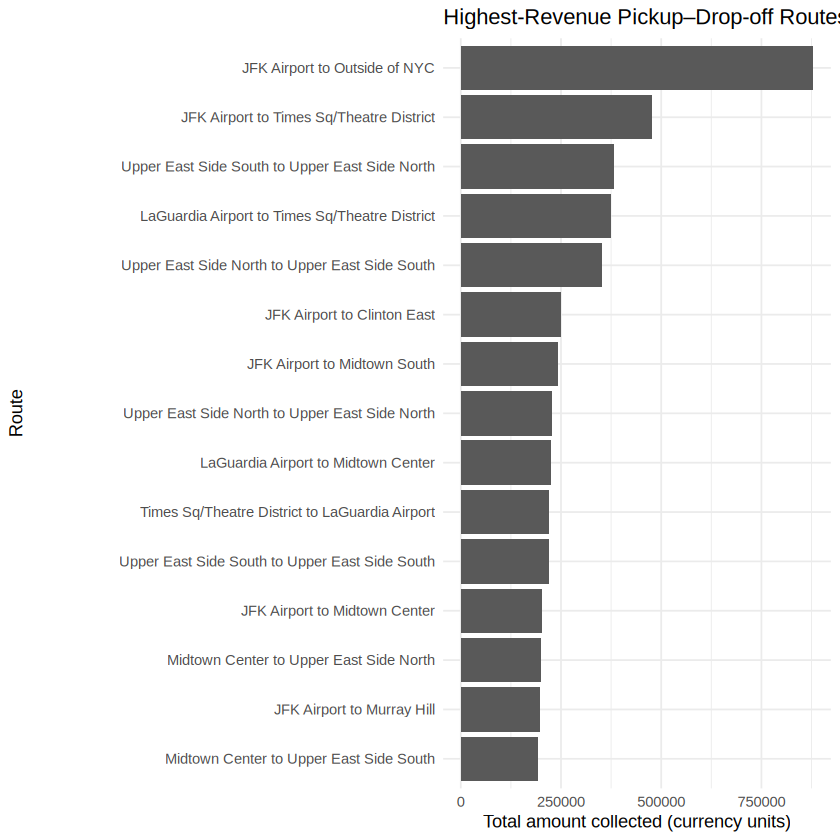

In [30]:
ggplot(highest_revenue_routes, aes(
  x = reorder(paste(pickup_zone, "to", dropoff_zone), total_revenue),
  y = total_revenue
)) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Highest-Revenue Pickup–Drop-off Routes",
    x = "Route",
    y = "Total amount collected (currency units)"
  ) +
  theme_minimal()

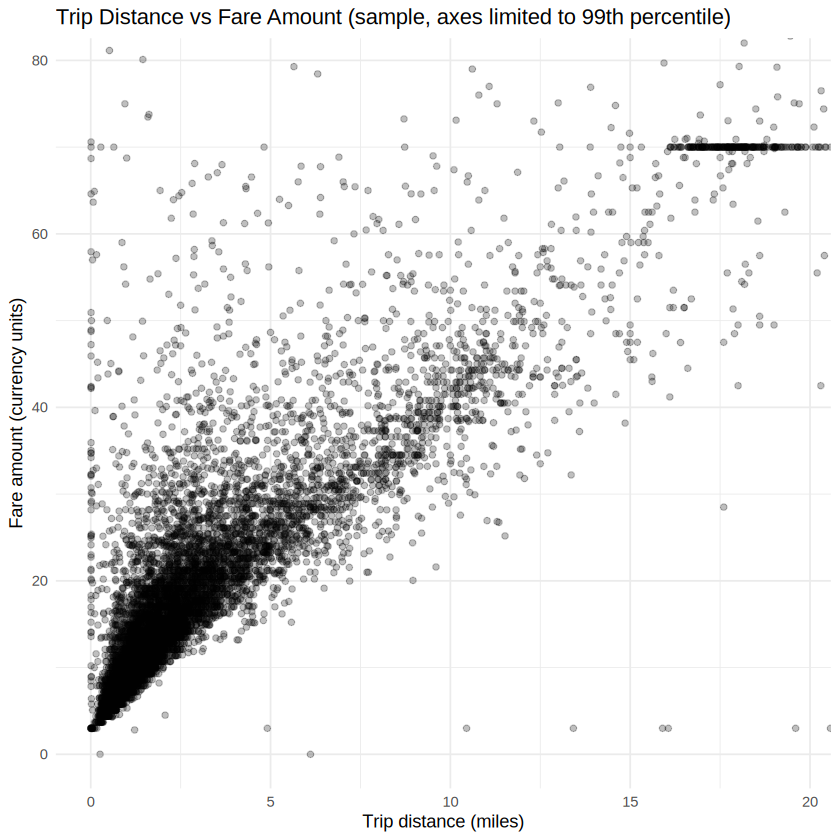

In [31]:
ggplot(trips[sample(.N, min(.N, 10000))], aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.25) +
  coord_cartesian(xlim = quantile(trips$trip_distance, c(0, 0.99), na.rm = TRUE),
                  ylim = quantile(trips$fare_amount, c(0, 0.99), na.rm = TRUE)) +
  labs(
    title = "Trip Distance vs Fare Amount (sample, axes limited to 99th percentile)",
    x = "Trip distance (miles)",
    y = "Fare amount (currency units)"
  ) +
  theme_minimal()

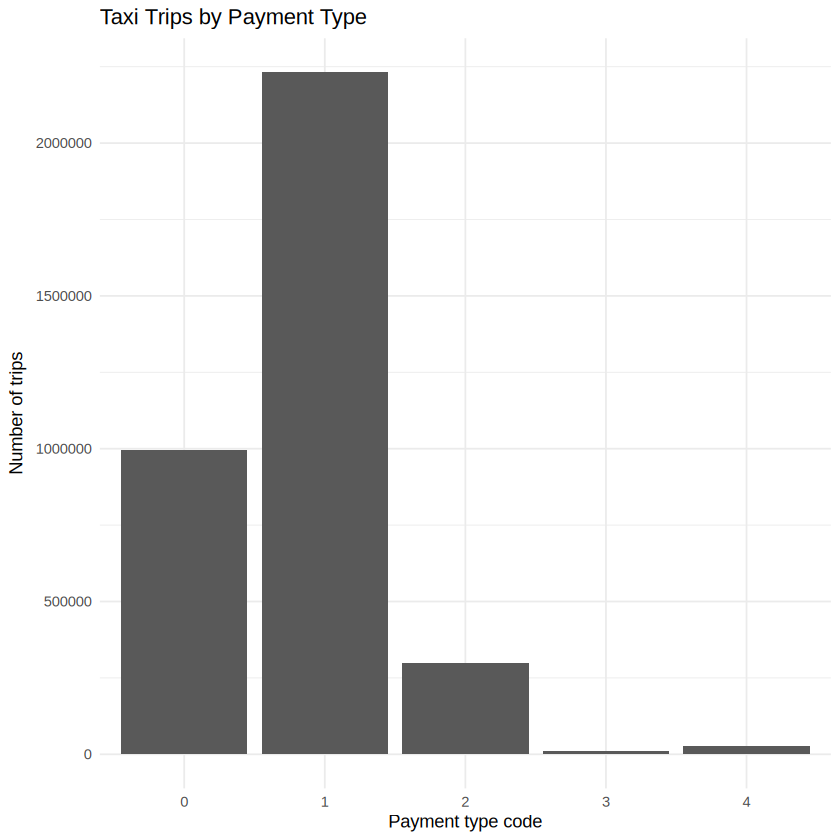

In [32]:
ggplot(payment_distribution, aes(x = factor(payment_type), y = trip_count)) +
  geom_col() +
  labs(
    title = "Taxi Trips by Payment Type",
    x = "Payment type code",
    y = "Number of trips"
  ) +
  theme_minimal()

### Brief interpretation prompts

Use the actual outputs and plots to write observations:
- Which hour and weekday have the most trips?
- Which routes are most frequent, and which generate the most total revenue?
- How does average fare change with trip distance?
- Which payment type is most common?
- Are any unusually high distances, fares, or durations visible?

## 9. Critical analysis and recommendation

Use the measured results above to complete the comparison. Do not assume a method is faster before looking at the benchmark output.

In [33]:
performance_comparison <- data.table(
  approach = c(
    "Base R table",
    "Vectorized tabulate",
    "data.table grouping",
    "lapply repeated count"
  ),
  typical_strength = c(
    "Simple and familiar",
    "Efficient for fixed integer categories",
    "Flexible grouping and joins on large tables",
    "Useful for applying a function repeatedly"
  ),
  tradeoff = c(
    "May create intermediate objects",
    "Requires suitable integer-coded categories",
    "Syntax can be less familiar to beginners",
    "Repeated scans can be expensive"
  )
)

performance_comparison

approach,typical_strength,tradeoff
<chr>,<chr>,<chr>
Base R table,Simple and familiar,May create intermediate objects
Vectorized tabulate,Efficient for fixed integer categories,Requires suitable integer-coded categories
data.table grouping,Flexible grouping and joins on large tables,Syntax can be less familiar to beginners
lapply repeated count,Useful for applying a function repeatedly,Repeated scans can be expensive
